In [23]:
print("Hello, World!")

Hello, World!



######################################################################
CROP: WHEAT
######################################################################
Train: 476  Test: 120  Val (2023): 159
Computing SHAP importances on full traintest data...
Feature set sizes: {'All 140': 140, 'Top 20': 20, 'Top 30': 30, 'SHAP+corr (50)': 50}
Year-based CV folds: 4 folds ([np.float64(2019.0), np.float64(2020.0), np.float64(2021.0), np.float64(2022.0)])

  Feature set: All 140 (140 features)

    Tuning XGBoost...
      Best params: {'model__colsample_bytree': 0.6, 'model__learning_rate': np.float64(0.26690431824362526), 'model__max_depth': 3, 'model__n_estimators': 364, 'model__reg_alpha': np.float64(0.001158417231054399), 'model__subsample': 0.7}
      CV AUC: 0.740  Test AUC: 0.913  Val AUC: 0.964

    Tuning Logistic Regression...
      Best params: {'model__C': np.float64(0.0010090061869151559), 'model__max_iter': 2000, 'model__solver': 'saga'}
      CV AUC: 0.750  Test AUC: 0.870  Val AUC: 0.

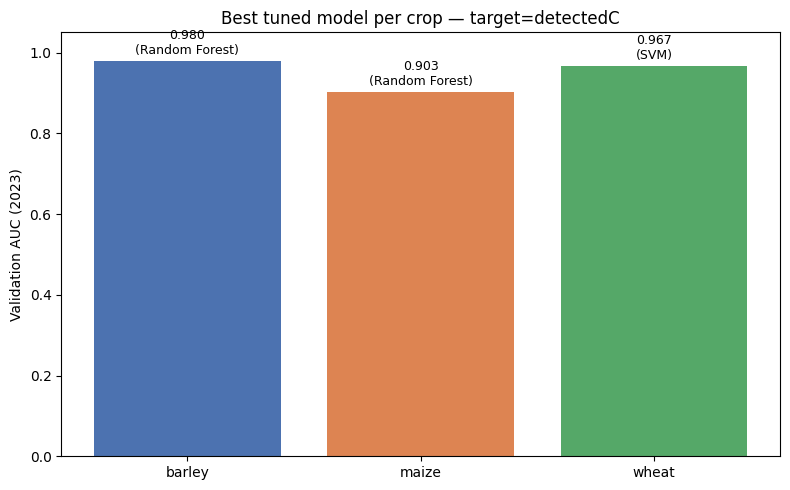

In [24]:
"""
feature_reduction_and_tuning_per_crop.py
=========================================
Per-crop version of the feature reduction + tuning pipeline.

Step 1: Feature reduction (3 variants using SHAP + correlation), computed
        separately per crop.
Step 2: Hyperparameter tuning with year-based CV, using a crop-specific
        model shortlist (chosen from the initial 7-model screening),
        with CatBoost always included as the newly-added candidate.
Step 3: Compare all variants on the 2023 validation set, per crop.
Step 4: Combine results across crops, save summary table + comparison plot.

ASSUMPTION: the crop column is named "crop" in sample_level_dataset.csv.
If it's named differently, change CROP_COL below.
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split, RandomizedSearchCV, PredefinedSplit
)
from sklearn.metrics import roc_auc_score, classification_report
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from scipy.stats import loguniform, randint

# ── CONFIG ───────────────────────────────────────────────────────────────
INPUT_PATH   = "sample_level_dataset.csv"
RANDOM_STATE = 42
CROP_COL     = "product_harmonised"          # <- change if your column is named differently
CROPS        = ["wheat", "barley", "maize"]
TARGET       = "detectedC"

# Per-crop model shortlist, based on the initial 7-model screening results.
# CatBoost is added everywhere since it wasn't part of that screening.
CROP_MODELS = {
    "barley": ["Naive Bayes", "Random Forest", "LightGBM", "Logistic Regression", "CatBoost"],
    "maize":  ["Random Forest", "LightGBM", "XGBoost", "SVM", "CatBoost"],
    "wheat":  ["XGBoost", "Logistic Regression", "SVM", "Naive Bayes", "CatBoost"],
}

N_ITER = 40  # RandomizedSearchCV iterations per (model, feature set)


# ── HELPERS ──────────────────────────────────────────────────────────────
def fix_dutch_numeric_col(series):
    if series.dtype not in (object, "string"):
        return series
    def clean(v):
        if pd.isna(v):
            return v
        parts = str(v).strip().split(".")
        return parts[0] + "." + parts[1] if len(parts) > 2 else str(v)
    return pd.to_numeric(series.apply(clean), errors="coerce")


def make_pipeline(base_est, scale):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", base_est))
    return Pipeline(steps)


def build_search_spaces(pos_weight):
    """Search spaces + base estimators + scaling flags for all candidate models."""
    search_spaces = {
        "Logistic Regression": {
            "model__C":        loguniform(1e-3, 1e2),
            "model__solver":   ["lbfgs", "saga"],
            "model__max_iter": [2000],
        },
        "Random Forest": {
            "model__n_estimators":     randint(100, 600),
            "model__max_depth":        randint(3, 15),
            "model__min_samples_leaf": randint(3, 20),
            "model__max_features":     ["sqrt", "log2", 0.3, 0.5],
        },
        "XGBoost": {
            "model__n_estimators":     randint(100, 600),
            "model__max_depth":        randint(2, 8),
            "model__learning_rate":    loguniform(0.01, 0.3),
            "model__subsample":        [0.6, 0.7, 0.8, 1.0],
            "model__colsample_bytree": [0.6, 0.7, 0.8, 1.0],
            "model__reg_alpha":        loguniform(1e-3, 10),
        },
        "CatBoost": {
            "model__iterations":      randint(100, 600),
            "model__depth":           randint(3, 8),
            "model__learning_rate":   loguniform(0.01, 0.2),
            "model__l2_leaf_reg":     randint(1, 10),
            "model__random_strength": loguniform(0.1, 5),
        },
        "LightGBM": {
            "model__n_estimators":     randint(100, 600),
            "model__max_depth":        randint(3, 12),
            "model__num_leaves":       randint(15, 127),
            "model__learning_rate":    loguniform(0.01, 0.3),
            "model__subsample":        [0.6, 0.7, 0.8, 1.0],
            "model__colsample_bytree": [0.6, 0.7, 0.8, 1.0],
            "model__reg_alpha":        loguniform(1e-3, 10),
        },
        "Naive Bayes": {
            "model__var_smoothing": loguniform(1e-11, 1e-7),
        },
        "SVM": {
            "model__C":      loguniform(1e-2, 1e2),
            "model__kernel":  ["rbf", "linear"],
            "model__gamma":  ["scale", "auto"],
        },
    }

    base_estimators = {
        "Logistic Regression": LogisticRegression(
            class_weight="balanced", random_state=RANDOM_STATE
        ),
        "Random Forest": RandomForestClassifier(
            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
        ),
        "XGBoost": XGBClassifier(
            scale_pos_weight=pos_weight, random_state=RANDOM_STATE,
            eval_metric="logloss", verbosity=0
        ),
        "CatBoost": CatBoostClassifier(
            auto_class_weights="Balanced", random_seed=RANDOM_STATE,
            verbose=0, eval_metric="AUC"
        ),
        "LightGBM": LGBMClassifier(
            class_weight="balanced", random_state=RANDOM_STATE, verbosity=-1
        ),
        "Naive Bayes": GaussianNB(),
        "SVM": SVC(
            class_weight="balanced", probability=True, random_state=RANDOM_STATE
        ),
    }

    use_scale = {
        "Logistic Regression": True,
        "Random Forest":       False,
        "XGBoost":             False,
        "CatBoost":            False,
        "LightGBM":            False,
        "Naive Bayes":         True,
        "SVM":                 True,
    }
    return search_spaces, base_estimators, use_scale


def get_feature_sets(X_traintest, y_traintest, features):
    """SHAP importance on an LR fit to the full traintest set, then build
    the top-20 / top-30 / SHAP+corr variants."""
    imputer = SimpleImputer(strategy="median")
    scaler  = StandardScaler()
    X_imp   = imputer.fit_transform(X_traintest)
    X_sc    = scaler.fit_transform(X_imp)
    X_df    = pd.DataFrame(X_sc, columns=features)

    lr_full = LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE
    )
    lr_full.fit(X_df, y_traintest)

    masker = shap.maskers.Independent(X_df, max_samples=len(X_df))
    explainer = shap.LinearExplainer(lr_full, masker=masker)
    shap_values = explainer(X_df)
    mean_shap = pd.Series(
        np.abs(shap_values.values).mean(axis=0), index=features
    ).sort_values(ascending=False)

    features_A = mean_shap.head(20).index.tolist()
    features_B = mean_shap.head(30).index.tolist()

    shap_threshold = mean_shap.mean()
    features_above = mean_shap[mean_shap >= shap_threshold].index.tolist()

    X_imp_df = pd.DataFrame(X_imp, columns=features)
    corr_matrix = X_imp_df[features_above].corr().abs()
    upper = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )
    to_drop = set()
    for col in upper.columns:
        correlated_with = upper.index[upper[col] > 0.90].tolist()
        for partner in correlated_with:
            drop = col if mean_shap[col] < mean_shap[partner] else partner
            to_drop.add(drop)
    features_C = [f for f in features_above if f not in to_drop]

    return {
        f"All {len(features)}": features,
        "Top 20":                features_A,
        "Top 30":                features_B,
        f"SHAP+corr ({len(features_C)})": features_C,
    }, mean_shap


def get_year_cv(traintest_df):
    years = traintest_df["harvest_year"].values
    val_fold = np.full(len(years), -1)
    unique_years = sorted(traintest_df["harvest_year"].unique())
    for i, yr in enumerate(unique_years):
        val_fold[years == yr] = i
    return PredefinedSplit(test_fold=val_fold), unique_years


# ── LOAD & CLEAN (shared across crops) ─────────────────────────────────
df = pd.read_csv(INPUT_PATH, low_memory=False)
weather_cols = [c for c in df.columns if c.startswith("month_") or c.startswith("week_")]
for col in weather_cols:
    df[col] = fix_dutch_numeric_col(df[col])
FEATURES = weather_cols

# ── MAIN PER-CROP LOOP ──────────────────────────────────────────────────
all_results = []
best_pipelines = {}  # (crop, model, feature_set) -> (pipeline, feat_cols)

for crop in CROPS:
    print(f"\n{'#'*70}\nCROP: {crop.upper()}\n{'#'*70}")

    crop_df = df[df[CROP_COL] == crop].copy()
    val_df       = crop_df[crop_df["harvest_year"] == 2023].copy()
    traintest_df = crop_df[crop_df["harvest_year"] != 2023].copy()

    X_traintest = traintest_df[FEATURES]
    y_traintest = traintest_df[TARGET]
    X_val       = val_df[FEATURES]
    y_val       = val_df[TARGET]

    X_train, X_test, y_train, y_test = train_test_split(
        X_traintest, y_traintest,
        test_size=0.2, stratify=y_traintest, random_state=RANDOM_STATE,
    )
    print(f"Train: {len(X_train)}  Test: {len(X_test)}  Val (2023): {len(X_val)}")

    if y_traintest.nunique() < 2 or y_val.nunique() < 2:
        print(f"  Skipping {crop}: not enough class variation in this split.")
        continue

    print("Computing SHAP importances on full traintest data...")
    feature_sets, mean_shap = get_feature_sets(X_traintest, y_traintest, FEATURES)
    print(f"Feature set sizes: { {k: len(v) for k, v in feature_sets.items()} }")

    year_cv, unique_years = get_year_cv(traintest_df)
    print(f"Year-based CV folds: {year_cv.get_n_splits()} folds ({unique_years})")

    pos_weight = (y_traintest == 0).sum() / (y_traintest == 1).sum()
    search_spaces, base_estimators, use_scale = build_search_spaces(pos_weight)

    models_for_crop = CROP_MODELS[crop]

    for feat_name, feat_cols in feature_sets.items():
        print(f"\n  {'='*60}\n  Feature set: {feat_name} ({len(feat_cols)} features)\n  {'='*60}")
        X_tr = X_train[feat_cols]
        X_te = X_test[feat_cols]
        X_v  = X_val[feat_cols]
        X_tt = X_traintest[feat_cols]

        for model_name in models_for_crop:
            base_est = base_estimators[model_name]
            print(f"\n    Tuning {model_name}...")
            pipeline = make_pipeline(base_est, scale=use_scale[model_name])
            search = RandomizedSearchCV(
                pipeline,
                param_distributions=search_spaces[model_name],
                n_iter=N_ITER,
                scoring="roc_auc",
                cv=year_cv,
                random_state=RANDOM_STATE,
                n_jobs=-1,
                refit=True,
            )
            search.fit(X_tt, y_traintest)
            best = search.best_estimator_
            cv_auc   = search.best_score_
            test_auc = roc_auc_score(y_test, best.predict_proba(X_te)[:, 1])
            val_auc  = roc_auc_score(y_val,  best.predict_proba(X_v)[:, 1])

            print(f"      Best params: {search.best_params_}")
            print(f"      CV AUC: {cv_auc:.3f}  Test AUC: {test_auc:.3f}  Val AUC: {val_auc:.3f}")

            all_results.append({
                "Crop":         crop,
                "Feature set":  feat_name,
                "Model":        model_name,
                "N features":   len(feat_cols),
                "CV AUC":       round(cv_auc, 3),
                "Test AUC":     round(test_auc, 3),
                "Val AUC":      round(val_auc, 3),
                "AUC gap":      round(test_auc - val_auc, 3),
                "Best params":  search.best_params_,
            })
            best_pipelines[(crop, model_name, feat_name)] = (best, feat_cols)

# ── RESULTS TABLE ───────────────────────────────────────────────────────
results_df = pd.DataFrame(all_results).sort_values(
    ["Crop", "Val AUC"], ascending=[True, False]
)
print("\n" + "="*70)
print(f"FULL RESULTS — target={TARGET}, sorted by Crop + Val AUC")
print("="*70)
print(results_df[["Crop", "Feature set", "Model", "N features",
                   "CV AUC", "Test AUC", "Val AUC", "AUC gap"]].to_string(index=False))
results_df.to_csv("tuning_results_per_crop_detectedC.csv", index=False)

# ── BEST MODEL PER CROP: BAR CHART + CLASSIFICATION REPORT ─────────────
best_per_crop = results_df.loc[results_df.groupby("Crop")["Val AUC"].idxmax()]
print("\n" + "="*70)
print("BEST MODEL PER CROP (by Val AUC)")
print("="*70)
print(best_per_crop[["Crop", "Feature set", "Model", "N features",
                      "CV AUC", "Test AUC", "Val AUC", "AUC gap"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(best_per_crop["Crop"], best_per_crop["Val AUC"], color=["#4C72B0", "#DD8452", "#55A868"])
for i, (crop, val) in enumerate(zip(best_per_crop["Crop"], best_per_crop["Val AUC"])):
    model_label = best_per_crop.iloc[i]["Model"]
    ax.text(i, val + 0.01, f"{val:.3f}\n({model_label})", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Validation AUC (2023)")
ax.set_title(f"Best tuned model per crop — target={TARGET}")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig("best_model_per_crop_tuned_detectedC.png", dpi=150)
print("\nPlot saved -> best_model_per_crop_tuned_detectedC.png")

for _, row in best_per_crop.iterrows():
    crop = row["Crop"]
    model_name = row["Model"]
    feat_name = row["Feature set"]
    best, feat_cols = best_pipelines[(crop, model_name, feat_name)]

    crop_df = df[df[CROP_COL] == crop].copy()
    val_df = crop_df[crop_df["harvest_year"] == 2023].copy()
    X_v = val_df[feat_cols]
    y_v = val_df[TARGET]
    y_pred = best.predict(X_v)

    print(f"\n{'-'*60}\nClassification report — {crop} — {model_name} ({feat_name})\n{'-'*60}")
    print(classification_report(y_v, y_pred))

In [25]:
#generalization
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
)

metric_rows = []

for _, row in results_df.iterrows():

    crop = row["Crop"]
    model = row["Model"]
    feat = row["Feature set"]

    best_model, feat_cols = best_pipelines[(crop, model, feat)]

    crop_df = df[df[CROP_COL] == crop].copy()
    val_df = crop_df[crop_df["harvest_year"] == 2023]

    X = val_df[feat_cols]
    y = val_df[TARGET]

    prob = best_model.predict_proba(X)[:,1]
    pred = best_model.predict(X)

    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()

    specificity = tn / (tn + fp) if (tn+fp) else np.nan
    sensitivity = tp / (tp + fn) if (tp+fn) else np.nan

    metric_rows.append({

        "Crop": crop,
        "Model": model,
        "Feature set": feat,

        "ROC AUC": roc_auc_score(y, prob),
        "Accuracy": accuracy_score(y, pred),
        "Balanced Acc": balanced_accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred),
        "Specificity": specificity,
        "F1": f1_score(y, pred),
        "MCC": matthews_corrcoef(y, pred)

    })

metrics_df = pd.DataFrame(metric_rows)
for crop in metrics_df["Crop"].unique():

    print("\n")
    print("="*90)
    print(crop.upper())
    print("="*90)

    display(
        metrics_df[metrics_df["Crop"]==crop]
        .sort_values("ROC AUC", ascending=False)
        .round(3)
    )




BARLEY


,Crop,Model,Feature set,ROC AUC,Accuracy,Balanced Acc,Precision,Recall,Specificity,F1,MCC
0,barley,Random Forest,All 140,0.980,0.587,0.500,0.587,1.000,0.000,0.740,0.000
1,barley,LightGBM,SHAP+corr (46),0.980,0.611,0.529,0.602,1.000,0.058,0.751,0.186
2,barley,CatBoost,SHAP+corr (46),0.980,0.825,0.788,0.771,1.000,0.577,0.871,0.667
3,barley,Logistic Regression,All 140,0.977,0.905,0.893,0.888,0.959,0.827,0.922,0.804
4,barley,Random Forest,Top 20,0.977,0.825,0.788,0.771,1.000,0.577,0.871,0.667
5,barley,Random Forest,Top 30,0.977,0.802,0.760,0.747,1.000,0.519,0.855,0.623
6,barley,CatBoost,Top 30,0.977,0.881,0.864,0.855,0.959,0.769,0.904,0.757
7,barley,Logistic Regression,SHAP+corr (46),0.968,0.905,0.893,0.888,0.959,0.827,0.922,0.804
8,barley,Random Forest,SHAP+corr (46),0.963,0.825,0.788,0.771,1.000,0.577,0.871,0.667
9,barley,CatBoost,Top 20,0.959,0.825,0.788,0.771,1.000,0.577,0.871,0.667




MAIZE


,Crop,Model,Feature set,ROC AUC,Accuracy,Balanced Acc,Precision,Recall,Specificity,F1,MCC
20,maize,Random Forest,Top 20,0.903,0.737,0.756,0.636,0.875,0.636,0.737,0.511
21,maize,Random Forest,All 140,0.847,0.421,0.500,0.421,1.000,0.000,0.593,0.000
22,maize,CatBoost,Top 20,0.847,0.737,0.756,0.636,0.875,0.636,0.737,0.511
23,maize,CatBoost,SHAP+corr (47),0.847,0.684,0.727,0.571,1.000,0.455,0.727,0.510
24,maize,Random Forest,Top 30,0.790,0.474,0.528,0.438,0.875,0.182,0.583,0.077
25,maize,CatBoost,Top 30,0.790,0.421,0.500,0.421,1.000,0.000,0.593,0.000
26,maize,LightGBM,Top 20,0.756,0.737,0.756,0.636,0.875,0.636,0.737,0.511
27,maize,Random Forest,SHAP+corr (47),0.744,0.421,0.500,0.421,1.000,0.000,0.593,0.000
28,maize,XGBoost,All 140,0.710,0.474,0.528,0.438,0.875,0.182,0.583,0.077
29,maize,CatBoost,All 140,0.710,0.474,0.528,0.438,0.875,0.182,0.583,0.077




WHEAT


,Crop,Model,Feature set,ROC AUC,Accuracy,Balanced Acc,Precision,Recall,Specificity,F1,MCC
40,wheat,SVM,Top 20,0.967,0.786,0.762,0.725,0.989,0.535,0.837,0.605
41,wheat,XGBoost,All 140,0.964,0.547,0.494,0.551,0.989,0.000,0.707,-0.071
42,wheat,Logistic Regression,SHAP+corr (50),0.958,0.560,0.507,0.557,1.000,0.014,0.715,0.089
43,wheat,XGBoost,Top 20,0.953,0.931,0.935,0.975,0.898,0.972,0.935,0.865
44,wheat,CatBoost,Top 20,0.951,0.648,0.610,0.616,0.966,0.254,0.752,0.322
45,wheat,XGBoost,SHAP+corr (50),0.931,0.610,0.572,0.594,0.932,0.211,0.726,0.210
46,wheat,Logistic Regression,All 140,0.922,0.610,0.572,0.594,0.932,0.211,0.726,0.210
47,wheat,XGBoost,Top 30,0.921,0.642,0.603,0.612,0.966,0.239,0.749,0.308
48,wheat,Naive Bayes,Top 20,0.919,0.931,0.936,0.987,0.886,0.986,0.934,0.867
49,wheat,CatBoost,Top 30,0.914,0.692,0.667,0.664,0.898,0.437,0.763,0.383


barley	Logistic Regression	All 140. maize	Random Forest	Top 20.  wheat	XGBoost	Top 20	

In [26]:
#save all model metrics to csv
metrics_df.to_csv("tuning_results_per_crop_detectedC_metrics.csv", index=False)

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
)

metric_rows = []

for (crop, model, feat), (pipeline, feat_cols) in best_pipelines.items():

    crop_df = df[df[CROP_COL] == crop].copy()
    val_df = crop_df[crop_df["harvest_year"] == 2023]

    X = val_df[feat_cols]
    y = val_df[TARGET]

    prob = pipeline.predict_proba(X)[:, 1]
    pred = pipeline.predict(X)

    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan

    metric_rows.append({
        "Crop": crop,
        "Model": model,
        "Feature set": feat,
        "ROC AUC": roc_auc_score(y, prob),
        "Accuracy": accuracy_score(y, pred),
        "Balanced Acc": balanced_accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred),
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1": f1_score(y, pred),
        "MCC": matthews_corrcoef(y, pred),
    })

metrics_df = pd.DataFrame(metric_rows)

# Round values for readability
metrics_df = metrics_df.round(3)

# Save to CSV
metrics_df.to_csv("all_models_validation_metrics_2023_DetectedC.csv", index=False)

print("Saved: all_models_validation_metrics_2023_DetectedC.csv")

# Display by crop
for crop in sorted(metrics_df["Crop"].unique()):

    print("\n")
    print("=" * 90)
    print(crop.upper())
    print("=" * 90)

    display(
        metrics_df[metrics_df["Crop"] == crop]
        .sort_values("ROC AUC", ascending=False)
    )

Saved: all_models_validation_metrics_2023_DetectedC.csv


BARLEY


,Crop,Model,Feature set,ROC AUC,Accuracy,Balanced Acc,Precision,Recall,Sensitivity,Specificity,F1,MCC
21,barley,Random Forest,All 140,0.980,0.587,0.500,0.587,1.000,1.000,0.000,0.740,0.000
37,barley,LightGBM,SHAP+corr (46),0.980,0.611,0.529,0.602,1.000,1.000,0.058,0.751,0.186
39,barley,CatBoost,SHAP+corr (46),0.980,0.825,0.788,0.771,1.000,1.000,0.577,0.871,0.667
23,barley,Logistic Regression,All 140,0.977,0.905,0.893,0.888,0.959,0.959,0.827,0.922,0.804
34,barley,CatBoost,Top 30,0.977,0.881,0.864,0.855,0.959,0.959,0.769,0.904,0.757
31,barley,Random Forest,Top 30,0.977,0.802,0.760,0.747,1.000,1.000,0.519,0.855,0.623
26,barley,Random Forest,Top 20,0.977,0.825,0.788,0.771,1.000,1.000,0.577,0.871,0.667
38,barley,Logistic Regression,SHAP+corr (46),0.968,0.905,0.893,0.888,0.959,0.959,0.827,0.922,0.804
36,barley,Random Forest,SHAP+corr (46),0.963,0.825,0.788,0.771,1.000,1.000,0.577,0.871,0.667
29,barley,CatBoost,Top 20,0.959,0.825,0.788,0.771,1.000,1.000,0.577,0.871,0.667




MAIZE


,Crop,Model,Feature set,ROC AUC,Accuracy,Balanced Acc,Precision,Recall,Sensitivity,Specificity,F1,MCC
45,maize,Random Forest,Top 20,0.903,0.737,0.756,0.636,0.875,0.875,0.636,0.737,0.511
40,maize,Random Forest,All 140,0.847,0.421,0.500,0.421,1.000,1.000,0.000,0.593,0.000
49,maize,CatBoost,Top 20,0.847,0.737,0.756,0.636,0.875,0.875,0.636,0.737,0.511
59,maize,CatBoost,SHAP+corr (47),0.847,0.684,0.727,0.571,1.000,1.000,0.455,0.727,0.510
54,maize,CatBoost,Top 30,0.790,0.421,0.500,0.421,1.000,1.000,0.000,0.593,0.000
50,maize,Random Forest,Top 30,0.790,0.474,0.528,0.438,0.875,0.875,0.182,0.583,0.077
46,maize,LightGBM,Top 20,0.756,0.737,0.756,0.636,0.875,0.875,0.636,0.737,0.511
55,maize,Random Forest,SHAP+corr (47),0.744,0.421,0.500,0.421,1.000,1.000,0.000,0.593,0.000
42,maize,XGBoost,All 140,0.710,0.474,0.528,0.438,0.875,0.875,0.182,0.583,0.077
44,maize,CatBoost,All 140,0.710,0.474,0.528,0.438,0.875,0.875,0.182,0.583,0.077




WHEAT


,Crop,Model,Feature set,ROC AUC,Accuracy,Balanced Acc,Precision,Recall,Sensitivity,Specificity,F1,MCC
7,wheat,SVM,Top 20,0.967,0.786,0.762,0.725,0.989,0.989,0.535,0.837,0.605
0,wheat,XGBoost,All 140,0.964,0.547,0.494,0.551,0.989,0.989,0.000,0.707,-0.071
16,wheat,Logistic Regression,SHAP+corr (50),0.958,0.560,0.507,0.557,1.000,1.000,0.014,0.715,0.089
5,wheat,XGBoost,Top 20,0.953,0.931,0.935,0.975,0.898,0.898,0.972,0.935,0.865
9,wheat,CatBoost,Top 20,0.951,0.648,0.610,0.616,0.966,0.966,0.254,0.752,0.322
15,wheat,XGBoost,SHAP+corr (50),0.931,0.610,0.572,0.594,0.932,0.932,0.211,0.726,0.210
1,wheat,Logistic Regression,All 140,0.922,0.610,0.572,0.594,0.932,0.932,0.211,0.726,0.210
10,wheat,XGBoost,Top 30,0.921,0.642,0.603,0.612,0.966,0.966,0.239,0.749,0.308
8,wheat,Naive Bayes,Top 20,0.919,0.931,0.936,0.987,0.886,0.886,0.986,0.934,0.867
14,wheat,CatBoost,Top 30,0.914,0.692,0.667,0.664,0.898,0.898,0.437,0.763,0.383


In [ ]:
#SHAP
#for models: barley naive bayes with shap+corr(49), maize catboost with all 140, wheat naive bayes with shap+corr(59)
#barley	CatBoost	SHAP+corr (49). maize	CatBoost	All 140.  wheat	SVM	Top 20	



BARLEY | Logistic Regression | All 140


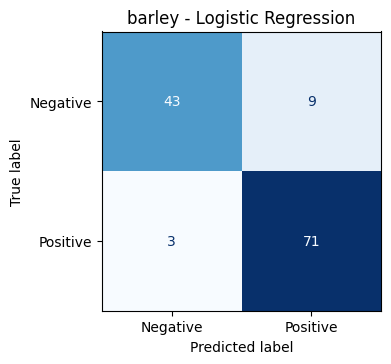

Background dataset has 126 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=126 when initializing the masker.


Computing SHAP values...


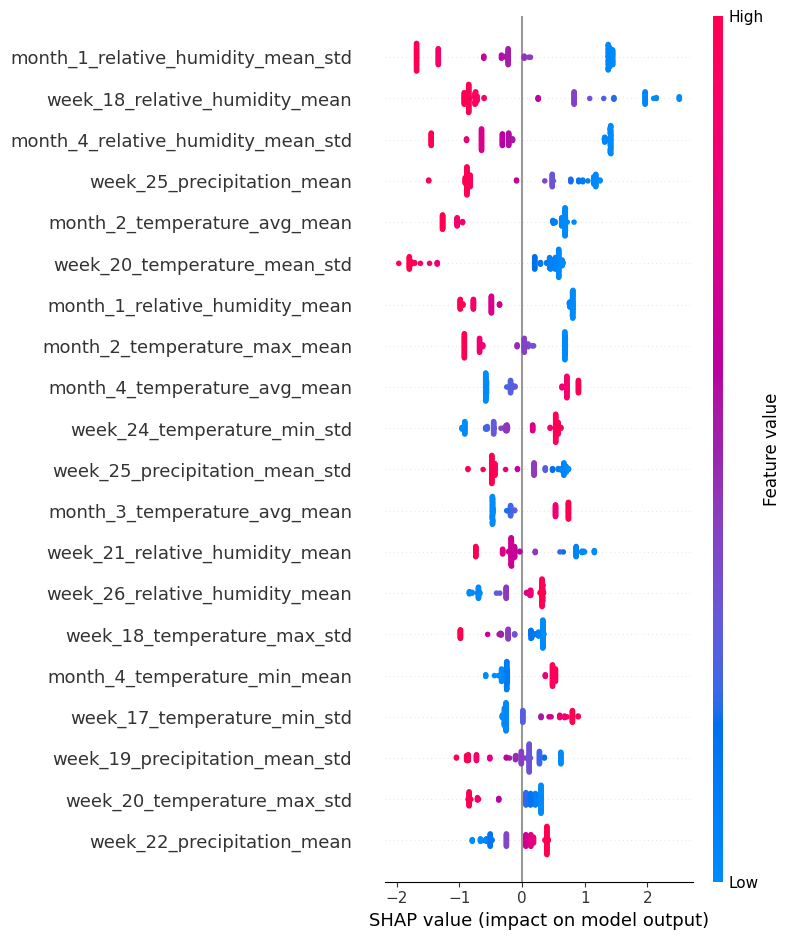

Saved: shap_outputs\barley_Logistic Regression_confusion_matrix_17-07-2026.png
Saved: shap_outputs\barley_Logistic Regression_shap_summary_17-07-2026.png

MAIZE | Random Forest | Top 20


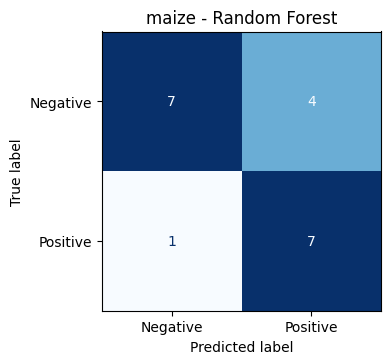

Computing SHAP values...


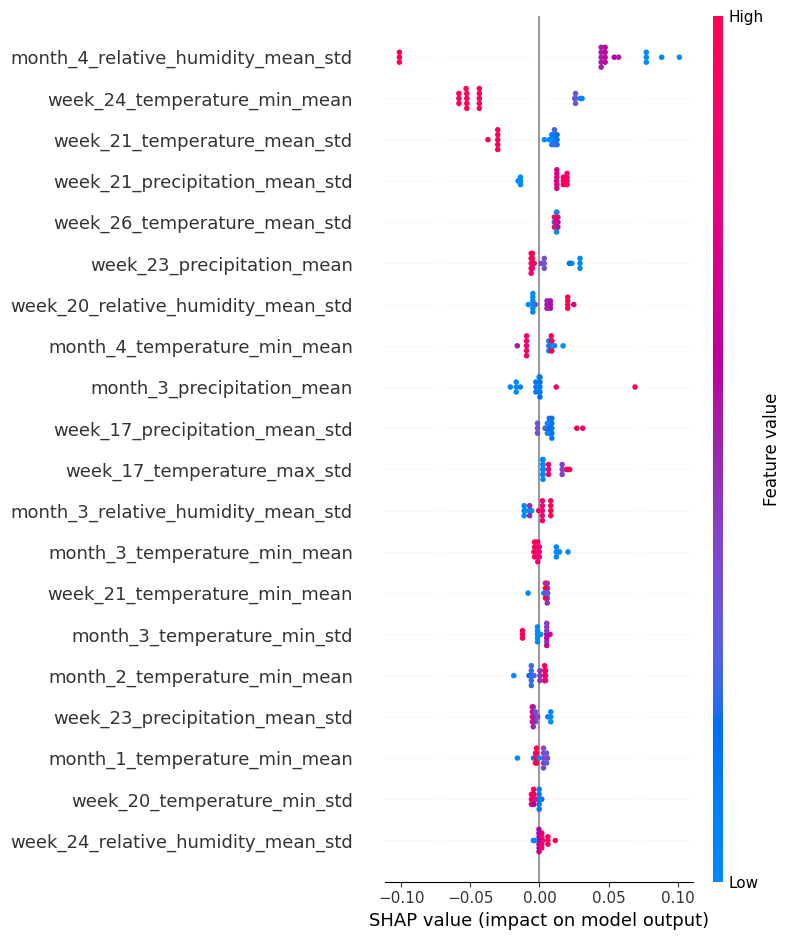

Saved: shap_outputs\maize_Random Forest_confusion_matrix_17-07-2026.png
Saved: shap_outputs\maize_Random Forest_shap_summary_17-07-2026.png

WHEAT | XGBoost | Top 20


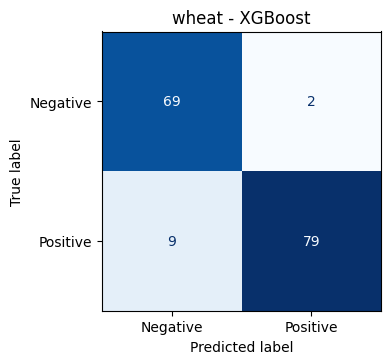

Computing SHAP values...


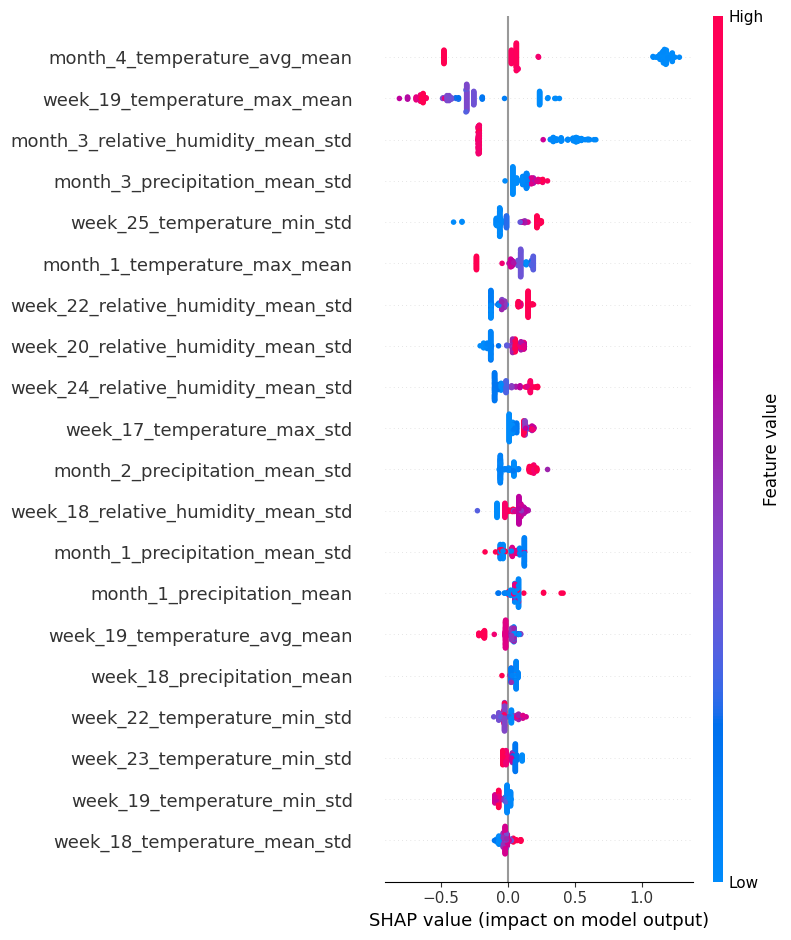

Saved: shap_outputs\wheat_XGBoost_confusion_matrix_17-07-2026.png
Saved: shap_outputs\wheat_XGBoost_shap_summary_17-07-2026.png


In [27]:
import numpy as np
import matplotlib.pyplot as plt
import shap
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# -------------------------------------------------------
# Output folder
# -------------------------------------------------------
OUTPUT_DIR = "shap_outputs"
import os
os.makedirs(OUTPUT_DIR, exist_ok=True)

# -------------------------------------------------------
# Date stamp for saved files
# -------------------------------------------------------
DATE_STAMP = "17-07-2026"

# -------------------------------------------------------
# Models to explain
# -------------------------------------------------------
models_to_plot = [
    ("barley", "Logistic Regression", "All 140"),
    ("maize", "Random Forest", "Top 20"),
    ("wheat", "XGBoost", "Top 20"),
]

# -------------------------------------------------------
# Loop
# -------------------------------------------------------
for crop, model_name, feat_name in models_to_plot:
    print("\n" + "=" * 80)
    print(f"{crop.upper()} | {model_name} | {feat_name}")
    print("=" * 80)

    pipeline, feat_cols = best_pipelines[(crop, model_name, feat_name)]
    crop_df = df[df[CROP_COL] == crop].copy()
    val_df = crop_df[crop_df["harvest_year"] == 2023].copy()

    X = val_df[feat_cols]
    y = val_df[TARGET]

    # ---------------------------------------------------
    # preprocessing (same as training pipeline)
    # ---------------------------------------------------
    X_proc = pipeline.named_steps["impute"].transform(X)
    if "scale" in pipeline.named_steps:
        X_proc = pipeline.named_steps["scale"].transform(X_proc)

    model = pipeline.named_steps["model"]

    # ---------------------------------------------------
    # Confusion matrix (matplotlib only)
    # ---------------------------------------------------
    y_pred = pipeline.predict(X)
    cm = confusion_matrix(y, y_pred)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"]
    )
    fig, ax = plt.subplots(figsize=(4, 4))
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{crop} - {model_name}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    plt.tight_layout()
    cm_path = os.path.join(OUTPUT_DIR, f"{crop}_{model_name}_confusion_matrix_{DATE_STAMP}.png")
    plt.savefig(cm_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # ---------------------------------------------------
    # SHAP
    # ---------------------------------------------------
    print("Computing SHAP values...")
    if isinstance(model, (RandomForestClassifier,
                          XGBClassifier,
                          LGBMClassifier,
                          CatBoostClassifier)):
        explainer = shap.TreeExplainer(model)
        shap_values = explainer(X_proc)
    elif isinstance(model, LogisticRegression):
        explainer = shap.LinearExplainer(model, X_proc)
        shap_values = explainer(X_proc)
    else:
        # Naive Bayes / SVM
        background = shap.sample(X_proc, min(100, len(X_proc)), random_state=42)
        explainer = shap.Explainer(
            model.predict_proba,
            background
        )
        shap_values = explainer(X_proc)

    # ---------------------------------------------------
    # Select positive class output if multi-output
    # (predict_proba-based explainers return shape
    # (n_samples, n_features, n_classes) for binary targets)
    # ---------------------------------------------------
    if len(shap_values.shape) == 3:
        shap_values_plot = shap_values[:, :, 1]
    else:
        shap_values_plot = shap_values

    # ---------------------------------------------------
    # SHAP plot (no seaborn dependency)
    # ---------------------------------------------------
    fig_shap = plt.figure()
    shap.summary_plot(
        shap_values_plot,
        X_proc,
        feature_names=feat_cols,
        max_display=20,
        show=False
    )
    shap_path = os.path.join(OUTPUT_DIR, f"{crop}_{model_name}_shap_summary_{DATE_STAMP}.png")
    plt.tight_layout()
    plt.savefig(shap_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig_shap)

    print(f"Saved: {cm_path}")
    print(f"Saved: {shap_path}")

Background dataset has 126 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=126 when initializing the masker.



BARLEY | Logistic Regression | All 140


<Figure size 640x480 with 0 Axes>

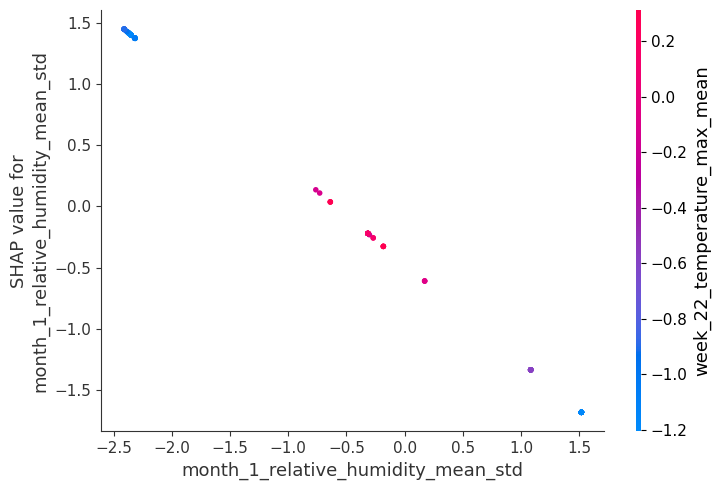

Saved: shap_outputs\barley_Logistic Regression_dependence_month_1_relative_humidity_mean_std_17-07-2026.png


<Figure size 640x480 with 0 Axes>

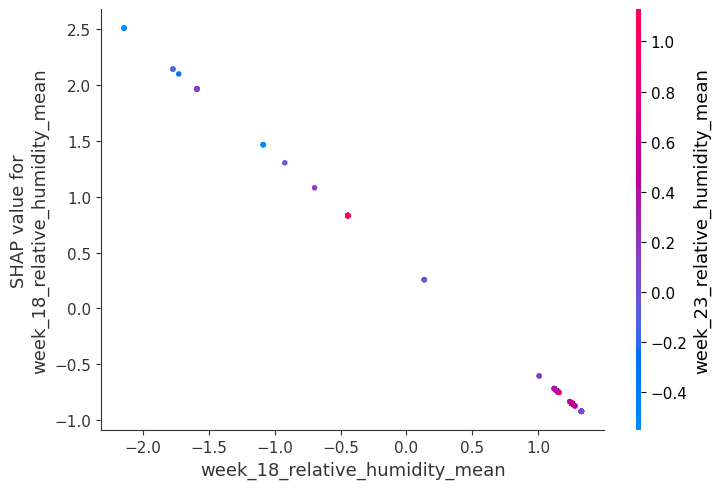

Saved: shap_outputs\barley_Logistic Regression_dependence_week_18_relative_humidity_mean_17-07-2026.png


<Figure size 640x480 with 0 Axes>

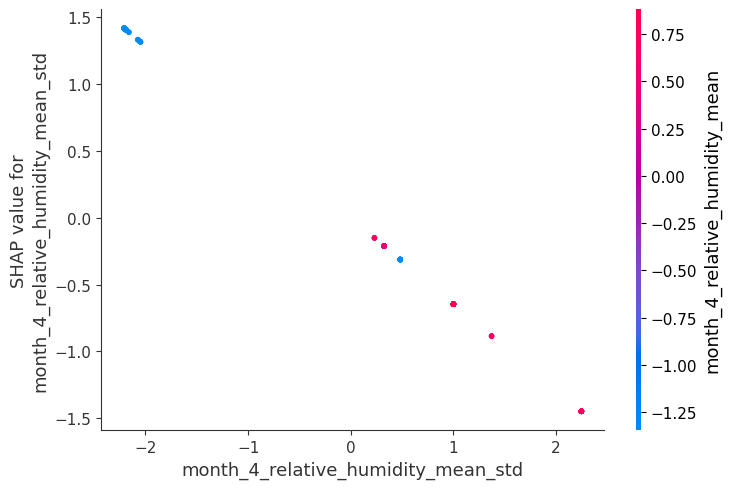

Saved: shap_outputs\barley_Logistic Regression_dependence_month_4_relative_humidity_mean_std_17-07-2026.png

MAIZE | Random Forest | Top 20


<Figure size 640x480 with 0 Axes>

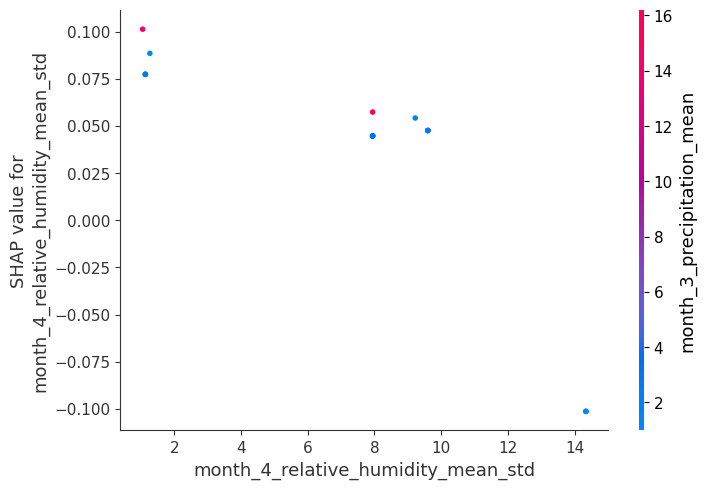

Saved: shap_outputs\maize_Random Forest_dependence_month_4_relative_humidity_mean_std_17-07-2026.png


<Figure size 640x480 with 0 Axes>

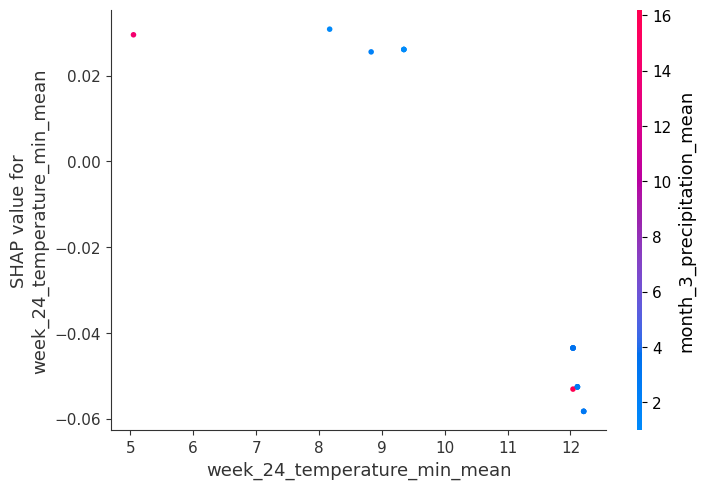

Saved: shap_outputs\maize_Random Forest_dependence_week_24_temperature_min_mean_17-07-2026.png


<Figure size 640x480 with 0 Axes>

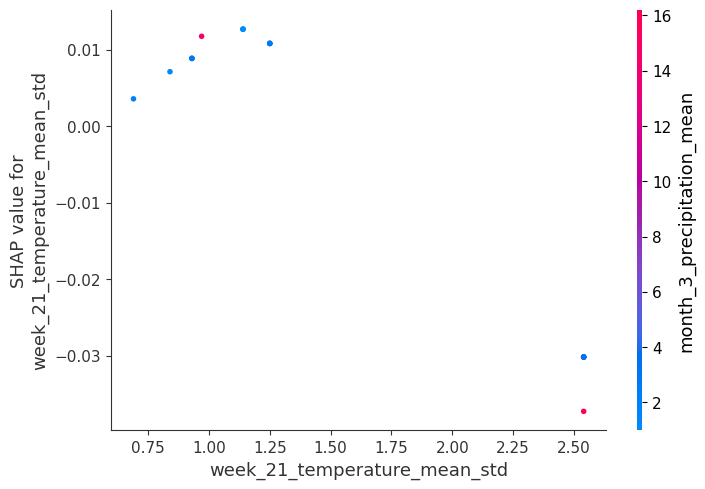

Saved: shap_outputs\maize_Random Forest_dependence_week_21_temperature_mean_std_17-07-2026.png

WHEAT | XGBoost | Top 20


<Figure size 640x480 with 0 Axes>

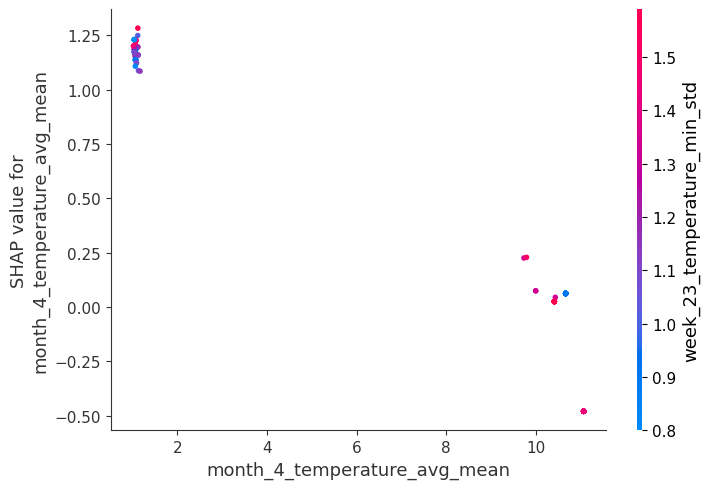

Saved: shap_outputs\wheat_XGBoost_dependence_month_4_temperature_avg_mean_17-07-2026.png


<Figure size 640x480 with 0 Axes>

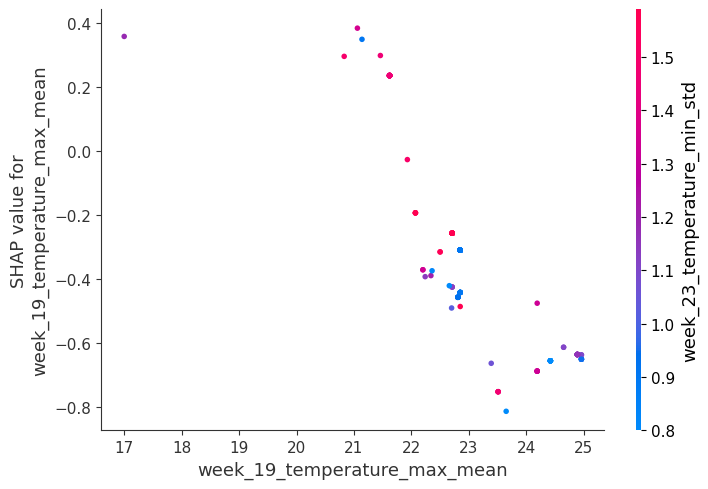

Saved: shap_outputs\wheat_XGBoost_dependence_week_19_temperature_max_mean_17-07-2026.png


<Figure size 640x480 with 0 Axes>

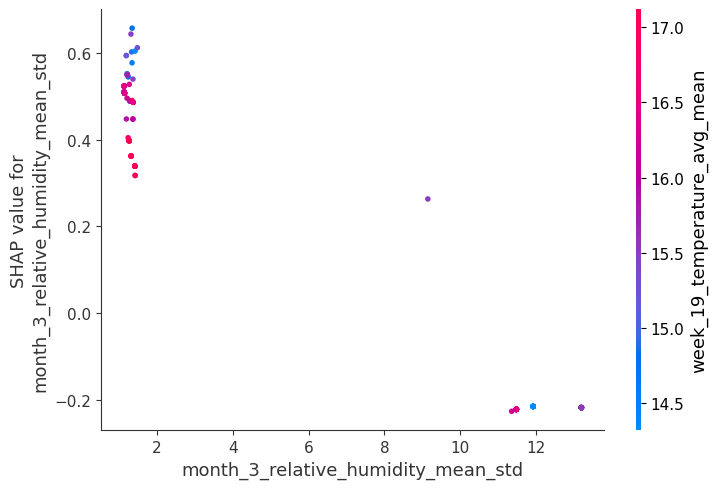

Saved: shap_outputs\wheat_XGBoost_dependence_month_3_relative_humidity_mean_std_17-07-2026.png

Saved separation score table: shap_outputs\shap_separation_scores_top20_17-07-2026.csv


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import os

OUTPUT_DIR = "shap_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DATE_STAMP = "17-07-2026"

models_to_plot = [
    ("barley", "Logistic Regression", "All 140"),
    ("maize", "Random Forest", "Top 20"),
    ("wheat", "XGBoost", "Top 20"),
]

TOP_N_DEPENDENCE = 3  # number of top features to plot dependence for

separation_scores = []  # collect for the summary table across crops

for crop, model_name, feat_name in models_to_plot:
    print("\n" + "=" * 80)
    print(f"{crop.upper()} | {model_name} | {feat_name}")
    print("=" * 80)

    pipeline, feat_cols = best_pipelines[(crop, model_name, feat_name)]
    crop_df = df[df[CROP_COL] == crop].copy()
    val_df = crop_df[crop_df["harvest_year"] == 2023].copy()

    X = val_df[feat_cols]

    X_proc = pipeline.named_steps["impute"].transform(X)
    if "scale" in pipeline.named_steps:
        X_proc = pipeline.named_steps["scale"].transform(X_proc)

    model = pipeline.named_steps["model"]

    # ---------------------------------------------------
    # Recompute SHAP values (same logic as before)
    # ---------------------------------------------------
    from sklearn.ensemble import RandomForestClassifier
    from xgboost import XGBClassifier
    from lightgbm import LGBMClassifier
    from catboost import CatBoostClassifier
    from sklearn.linear_model import LogisticRegression

    if isinstance(model, (RandomForestClassifier, XGBClassifier, LGBMClassifier, CatBoostClassifier)):
        explainer = shap.TreeExplainer(model)
        shap_values = explainer(X_proc)
    elif isinstance(model, LogisticRegression):
        explainer = shap.LinearExplainer(model, X_proc)
        shap_values = explainer(X_proc)
    else:
        # Naive Bayes / SVM
        background = shap.sample(X_proc, min(100, len(X_proc)), random_state=42)
        explainer = shap.Explainer(model.predict_proba, background)
        shap_values = explainer(X_proc)

    if len(shap_values.shape) == 3:
        shap_values_plot = shap_values[:, :, 1]
    else:
        shap_values_plot = shap_values

    X_proc_df = pd.DataFrame(X_proc, columns=feat_cols)

    # ---------------------------------------------------
    # 1. Dependence plots for top N features
    # ---------------------------------------------------
    mean_abs_shap = np.abs(shap_values_plot.values).mean(axis=0)
    top_idx = np.argsort(mean_abs_shap)[::-1][:TOP_N_DEPENDENCE]
    top_features = [feat_cols[i] for i in top_idx]

    for feat in top_features:
        fig = plt.figure()
        shap.dependence_plot(
            feat,
            shap_values_plot.values,
            X_proc_df,
            feature_names=feat_cols,
            show=False
        )
        dep_path = os.path.join(OUTPUT_DIR, f"{crop}_{model_name}_dependence_{feat}_{DATE_STAMP}.png")
        plt.tight_layout()
        plt.savefig(dep_path, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig)
        print(f"Saved: {dep_path}")

    # ---------------------------------------------------
    # 3. Quantitative separation score per feature
    # (mean SHAP in top tercile of feature value minus
    #  mean SHAP in bottom tercile -> larger = cleaner
    #  monotonic separation, smaller/near-zero = scattered)
    # ---------------------------------------------------
    for i, feat in enumerate(feat_cols):
        vals = X_proc_df[feat].values
        shaps = shap_values_plot.values[:, i]
        if np.all(np.isnan(vals)) or len(np.unique(vals)) < 3:
            continue
        low_thresh, high_thresh = np.nanpercentile(vals, [33, 67])
        low_mask = vals <= low_thresh
        high_mask = vals >= high_thresh
        if low_mask.sum() == 0 or high_mask.sum() == 0:
            continue
        sep_score = shaps[high_mask].mean() - shaps[low_mask].mean()
        separation_scores.append({
            "crop": crop,
            "model": model_name,
            "feature": feat,
            "mean_abs_shap": mean_abs_shap[i],
            "separation_score": sep_score
        })

# ---------------------------------------------------
# Save separation score table (top 20 per crop by mean_abs_shap)
# ---------------------------------------------------
sep_df = pd.DataFrame(separation_scores)
sep_df_top = (
    sep_df.sort_values(["crop", "mean_abs_shap"], ascending=[True, False])
    .groupby("crop")
    .head(20)
)
sep_path = os.path.join(OUTPUT_DIR, f"shap_separation_scores_top20_{DATE_STAMP}.csv")
sep_df_top.to_csv(sep_path, index=False)
print(f"\nSaved separation score table: {sep_path}")

In [ ]:
# ── CATBOOST THRESHOLD OPTIMISATION USING YEAR-BASED CV AND MACRO F1 ──────────────────
# - For Barley 140-feature SHAP+corr variant, which was the best overall model for barley.
